# Número reproductivo efectivo $R_t$ de varicela: cálculo nacional con casos diarios

Este cuaderno estima un $R_t$ nacional cada día para 2008–2025 a partir de los **registros individuales de Sivigila**, usando la fecha de notificación `FEC_NOT`. La salida es [`rt_national_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_daily.csv). En el [cuaderno de incidencia agregada](02_rt_nacional.ipynb), en cambio, se parte de totales semanales y se reconstruye una distribución diaria; aquí cada $I_d$ es el número de registros que realmente tienen `FEC_NOT=d`. El cambio elimina la incertidumbre de repartir un total semanal, pero no la demora ni los sesgos de notificación.

El **número reproductivo instantáneo** $R_t$ es el número esperado de infecciones secundarias por persona infectada si las condiciones de transmisión del día $t$ persistieran durante el período infeccioso de esa persona. La estimación que sigue aplica un modelo de renovación a **notificaciones**, no a infecciones observadas. Por tanto, su interpretación biológica exige supuestos adicionales sobre cómo las fechas de registro reflejan los contagios; se precisan antes de presentar los resultados.

## 1. Procedencia, unidad de análisis y filtros

Los [19 CSV anuales 2007–2025](../data/sivigila/csv/) son copias locales de los archivos individuales del evento 831 (varicela) del proyecto `data-processing`. Su [README](../data/sivigila/README.md) y [diccionario](../data/sivigila/dic_datos.md) explican los campos; la [tabla DIVIPOLA](../data/sivigila/DIVIPOLA-_Códigos_municipios_20261007.csv) determina qué códigos de municipio de residencia se aceptan. Sivigila entrega **registros individuales**; el agrupamiento semanal del [otro cuaderno](02_rt_nacional.ipynb) fue realizado en `data-processing`, no por Sivigila.

Para coincidir con la [serie semanal de referencia](../docs/data_processed/evolucion_semanal/weekly_series_2007_2025.csv), el programa comprueba `ANO` igual al año del archivo y `COD_EVE=831`; acepta municipios de residencia presentes en DIVIPOLA después de homologar `27086→27493`, `94663→94343` y `88000→88001`; excluye `AJUSTE` 6 o D; y extrae `FEC_NOT` en formato día/mes/año, ignorando el texto horario que sigue en algunos CSV. Una fecha no interpretable se excluye. **No se deduplican** notificaciones: cada fila incluida cuenta una vez, como en el agregado semanal. `INI_SIN` es inicio de síntomas y `SEMANA` es la semana registrada en el archivo, pero ninguno fija el día de esta serie. Los conteos son notificaciones, no una tasa por población.

Los archivos de origen están organizados por `ANO`, mientras que la semana epidemiológica de salida se calcula desde `FEC_NOT`: empieza el domingo y la semana 1 contiene el 4 de enero. Leer también el archivo de 2007 permite cubrir el inicio del año epidemiológico 2008. El período principal excluye 2007 por la discrepancia de cobertura documentada en el [README de datos](../data/README.md). El código lee los CSV en bloques de 50.000 filas, sin depender de rutas externas al repositorio.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gamma

# Resolve paths when the notebook runs from the repository root or notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from rt_daily_sivigila import daily_counts, build_daily_series, estimate_daily
from epiestim_parametric_weekly import discr_si

# Each eligible source row contributes one case to its FEC_NOT date; quality audits filters.
observed, quality = daily_counts()
# Build the daily calendar and reconcile its weekly sums with the reference CSV.
daily = build_daily_series(observed)
print("Auditoría de registros:", dict(quality))
print(f"Días del calendario: {len(daily):,}; notificaciones de 2008–2025: {daily.notifications.sum():,.0f}")
display(daily.head())

Auditoría de registros: {'source_rows': 1257304, 'included_rows': 1251524, 'missing_notification_date': 0}
Días del calendario: 6,580; notificaciones de 2008–2025: 1,224,776


,date,year,week,notifications,missing_week
0,2007-12-30,2008,1,25.0,False
1,2007-12-31,2008,1,48.0,False
2,2008-01-01,2008,1,39.0,False
3,2008-01-02,2008,1,100.0,False
4,2008-01-03,2008,1,87.0,False


## 2. Reconciliación semanal y semana sin dato

La serie contiene **todos los días** de los años epidemiológicos 2008–2025. Si no hay registros en un día de una semana observada, ese día tiene **cero notificaciones registradas**. Si falta el total de toda una semana, sus días quedan sin dato. En particular, el agregado nacional carece de 2008-S52: sus siete días, del **21 al 27 de diciembre de 2008**, permanecen `NaN`, aunque las semanas vecinas sí tienen conteos. Esto conserva la convención de auditoría del análisis previo; ausencia de una fila semanal no prueba ausencia de casos.

`build_daily_series` vuelve a sumar los siete días de **cada semana observada** y comprueba igualdad exacta con `weekly_series_2007_2025.csv`. También comprueba que una semana ausente no contenga casos diarios elegibles. Si falla una de esas condiciones, el cálculo se detiene. Esta es una prueba de **coherencia entre dos preparaciones de los mismos registros**, no una validación independiente de la vigilancia. El hueco divide la convolución serial en dos tramos: ninguna estimación usa los siete días faltantes como ceros ni arrastra infecciosidad conocida del tramo anterior al posterior.

In [2]:
# A missing reference week must contain exactly seven days with NaN counts.
missing = daily.loc[daily.missing_week, ["date", "year", "week", "notifications"]]
assert len(missing) == 7 and set(zip(missing.year, missing.week)) == {(2008, 52)}
assert missing.notifications.isna().all()
print("Semana sin dato:")
display(missing)
# min_count=1 retains NaN when every day in a week is missing.
weekly_check = daily.groupby(["year", "week"], as_index=False).agg(
    notifications=("notifications", lambda x: x.sum(min_count=1)))
display(weekly_check.loc[(weekly_check.year == 2008) & weekly_check.week.between(50, 53)])

Semana sin dato:


,date,year,week,notifications
357,2008-12-21,2008,52,NaN
358,2008-12-22,2008,52,NaN
359,2008-12-23,2008,52,NaN
360,2008-12-24,2008,52,NaN
361,2008-12-25,2008,52,NaN
362,2008-12-26,2008,52,NaN
363,2008-12-27,2008,52,NaN


,year,week,notifications
49,2008,50,165.0
50,2008,51,1.0
51,2008,52,NaN
52,2008,53,1.0


## 3. Intervalos entre casos, notificación y pesos diarios

Para un par transmisor $i$–caso secundario $j$, sean $T$ la fecha de **infección**, $O$ la de **inicio de síntomas**, $L=O-T$ el período de incubación y $N$ la fecha de **notificación**. El **intervalo de generación** $G_{ij}=T_j-T_i$ mide la separación entre infecciones. El **intervalo serial** $S_{ij}=O_j-O_i$ mide la separación entre inicios de síntomas. Se relacionan por

$$S_{ij}=G_{ij}+L_j-L_i.$$

Si ambos períodos de incubación tienen la misma media, pueden coincidir las medias de $G$ y $S$, pero su dispersión y forma no tienen por qué coincidir ([Lehtinen et al., 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC7879757/)). El intervalo de **notificación** tiene además otra diferencia. Con $D_k=N_k-O_k$ como demora del caso $k$,

$$N_j-N_i=S_{ij}+D_j-D_i.$$

Las demoras exactamente iguales se cancelarían; demoras parecidas o estables *en promedio* no eliminan su variación. Por eso aplicar pesos de intervalos seriales a fechas `FEC_NOT` supone que esas demoras no deforman materialmente los rezagos relevantes. El [análisis reproducible de demoras](03_demora_notificacion_sivigila.ipynb), realizado sobre registros individuales con ambas fechas interpretables, obtuvo $n=1.169.382$, mediana de **2 días**, rango intercuartílico **1–4 días** y **67,4 %** notificados entre el inicio de síntomas y tres días después. La proporción con demora mayor que siete días aumentó del **4,6 % en 2009–2011** al **17,7 % en 2019–2025**. Estos datos apoyan describir patrones de vigilancia a escala de semanas, pero **no verifican** que los rezagos entre notificaciones tengan la distribución serial supuesta. [Gostic et al. (2020)](https://doi.org/10.1371/journal.pcbi.1008409) explican cómo los retrasos de observación pueden alterar la fecha estimada de $R_t$.

Para varicela usamos la estimación de [Vink et al. (2014), tabla 3](https://doi.org/10.1093/aje/kwu209) basada en **184 intervalos** recogidos por [R. E. H. Simpson (1952)](https://doi.org/10.1016/S0140-6736(52)91357-3) en Inglaterra. Su distribución normal para $S$ tiene **media 14,1 días** y **desviación estándar 2,4 días**: el promedio entre inicios de síntomas de pares vinculados es 14,1 días y los tiempos individuales se dispersan alrededor de ese promedio con desviación 2,4. Esta última no es el error estándar de la media. Vink et al. obtuvieron además una media agrupada de 14,0 días entre tres estudios, cuya variabilidad se explora abajo. Ni la media ni la desviación fueron estimadas para Colombia; nuestros CSV tampoco identifican pares transmisor–secundario con los que recalcularlas ([Charniga et al., 2024](https://pmc.ncbi.nlm.nih.gov/articles/PMC11516000/)).

Para seguir la ruta `parametric_si` de EpiEstim aproximamos esos momentos con una **Gamma desplazada un día**: $S=1+X$, $X\sim\operatorname{Gamma}(\alpha,\theta)$, donde $\alpha=((\mu-1)/\sigma)^2$ es la forma y $\theta=\sigma^2/(\mu-1)$ la **escala**. Con $\mu=14{,}1$ y $\sigma=2{,}4$, [`discr_si()`](https://mrc-ide.github.io/EpiEstim/reference/discr_si.html) transforma la distribución continua en pesos $w_s$ para rezagos enteros $s\geq1$. Los pesos son no negativos y su suma es 1. La [comparación R–Python](04_comparacion_epiestim_r_python.ipynb) cotejó esta discretización con EpiEstim 2.4 en R. Aquí reutilizamos exactamente la misma función Python; el cálculo diario completo tiene una regla adicional de historia suficiente explicada en la sección 4 y no es una llamada a R.

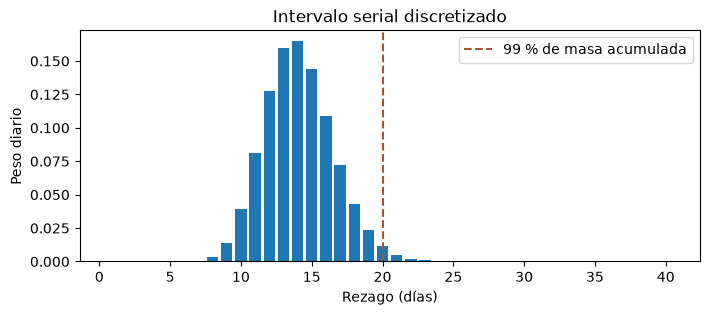

Suma de pesos hasta 89 días: 1.00000000; peso en el día 14: 0.165; rezago 99 %: 20 días


In [3]:
# Convert the continuous serial interval into one weight per daily lag.
weights = discr_si(np.arange(90), 14.1, 2.4)
# The first lag reaching 99% cumulative mass sets the minimum history.
lag_99 = int(np.searchsorted(np.cumsum(weights), .99))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(1, 41), weights[1:41], width=.8)
ax.axvline(lag_99, color="#a45632", ls="--", label="99 % de masa acumulada")
ax.set(xlabel="Rezago (días)", ylabel="Peso diario", title="Intervalo serial discretizado")
ax.legend()
plt.show()
print(f"Suma de pesos hasta 89 días: {weights.sum():.8f}; peso en el día 14: {weights[14]:.3f}; rezago 99 %: {lag_99} días")

## 4. Modelo de renovación, infectividad e historia suficiente

En el modelo ideal de [Fraser (2007)](https://doi.org/10.1371/journal.pone.0000758) y [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133), $C_d$ es el número **no observado** de infecciones nuevas en el día $d$. Si una cohorte de $C_{d-s}$ infectados de hace $s$ días recibe peso $w_s$, todas las cohortes anteriores aportan

$$\Lambda_d^{\mathrm{inf}}=\sum_{s\geq1}w_s C_{d-s},\qquad
\mathbb E[C_d\mid C_{<d},R_d]=R_d\Lambda_d^{\mathrm{inf}}.$$

La suma $\Lambda_d^{\mathrm{inf}}$ es una **cantidad calculada de incidencia previa ponderada por antigüedad**, en unidades de casos ponderados. Si hubo diez casos en un rezago con peso 0,2, aportan dos unidades a la suma; eso **no** afirma que se observaron dos personas infecciosas hoy. La igualdad solo fija una media condicional. [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133) añaden $C_d\mid C_{<d},R_d\sim\operatorname{Poisson}(R_d\Lambda_d^{\mathrm{inf}})$, que fija también la varianza condicional en el mismo valor de la media.

En los datos disponibles sustituimos la incidencia de infecciones $C_d$ por el conteo **observado de notificaciones** $I_d$ y calculamos $\Lambda_d=\sum_{s\geq1}w_sI_{d-s}$. Modelamos $I_d\mid I_{<d},R_d\sim\operatorname{Poisson}(R_d\Lambda_d)$. Se trata de una aproximación aplicada al proceso de registro: aunque $I_d$ sea un conteo real de filas del CSV, $\Lambda_d$ y $R_d$ siguen siendo cantidades de modelo. Tampoco se identifica quién contagió a quién.

Al comienzo de 2008 y después de 2008-S52 faltan casos anteriores que podrían contribuir a $\Lambda_d$. Para no publicar las estimaciones extremas que produce esa historia truncada, exigimos que **en cada día de los 14 de la ventana** la historia disponible cubra al menos el **99 % de la masa** de los pesos seriales. Con el escenario principal, eso exige al menos **20 días previos** dentro del tramo observado antes del primer día de la ventana. La primera ventana publicable termina el **1 de febrero de 2008**; después del hueco, el **30 de enero de 2009**. El umbral del 99 % es una decisión conservadora de calidad numérica, no elimina la historia realmente desconocida ni demuestra que el $R_t$ de reinicio sea correcto. Es más estricto que el mínimo de tiempo que usa EpiEstim; por ello esta serie no busca igualdad numérica completa con la salida diaria predeterminada del paquete.

## 5. Previa y posterior Gamma en una ventana de 14 días

Para cada día final $t$ definimos **un solo parámetro $R_t$**, supuesto constante durante los días $t-13,\ldots,t$. El modelo asigna a cada conteo diario de esa ventana media $R_t\Lambda_d$ y varianza condicional igual a esa media. La constancia local suaviza cambios rápidos: se publica una estimación **cada día**, pero cada una reúne 14 días de datos. Elegimos esa duración porque se acerca a la media serial bibliográfica de 14,1 días y cubre dos ciclos semanales de notificación; la [guía general de EpiEstim](https://mrc-ide.github.io/EpiEstim/articles/full_EpiEstim_vignette.html) sugiere empezar con ventanas al menos tan largas como la media serial. [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) no proponen una ventana óptima para $R_t$. En esta ruta de casos **diarios observados** no rige la restricción adicional de longitud mínima por agregación semanal de la [guía para datos agregados](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html).

La **previa** de cada $R_t$, antes de utilizar los conteos de su ventana, es $\operatorname{Gamma}(a=1,b=0{,}2)$, con **forma** $a$ y **tasa** $b$; no debe confundirse con la Gamma *de escala* usada para el intervalo serial. En una Gamma de tasa, $\mathbb E[R_t]=a/b$ y $\operatorname{DE}(R_t)=\sqrt a/b$. Elegir media y desviación estándar ambas iguales a 5 da $a=(5/5)^2=1$ y $b=5/5^2=0{,}2$, varianza 25 e intervalo previo central del 95 % aproximadamente $[0{,}13;18{,}44]$. La media 5 es una expectativa **previa** y la desviación 5 expresa dispersión amplia; no son estimaciones de varicela colombiana. El [suplemento de Cori et al. (2013), apéndice 10](https://bosailiteracy.org/wp-content/uploads/2020/05/Supplementary-Data.pdf) comparó previas de medias 1, 5, 10 y 50 con desviaciones iguales a sus medias; [Thompson et al. (2019)](https://doi.org/10.1016/j.epidem.2019.100356) emplearon 5 y 5 siguiendo a Cori, y [EpiEstim](https://mrc-ide.github.io/EpiEstim/reference/estimate_R.html) los usa por defecto.

La amplitud previa es coherente con no imponer el mismo rango estrecho a todas las ventanas nacionales. [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) documentan heterogeneidad espacial y estacional de la varicela colombiana; el [panel C de su Figura 4](https://pmc.ncbi.nlm.nih.gov/articles/PMC10503957/figure/jiad244-F4/) muestra componentes estacionales de la **tasa de contagio en otro modelo** para Cúcuta y Bogotá. Esas curvas no son valores de nuestro $R_t$ ni calibran $a$ o $b$. [Pawaskar et al. (2022)](https://doi.org/10.1016/j.vaccine.2022.07.012) documentan menor incidencia tras la vacunación, pero tampoco estiman esta previa. La elección sigue siendo metodológica y se contrasta abajo con una alternativa.

La conjugación Poisson–Gamma da la **posterior**, distribución después de incorporar los 14 conteos:

$$R_t\mid I\sim\operatorname{Gamma}\left(a+\sum_{d=t-13}^{t}I_d,\quad b+\sum_{d=t-13}^{t}\Lambda_d\right).$$

Así, $a=1$ se suma como un **pseudocaso** y $b=0{,}2$ como 0,2 unidades de infectividad acumulada. Publicamos la media posterior y sus cuantiles 2,5 % y 97,5 %. El intervalo entre esos cuantiles contiene el 95 % de probabilidad **condicional al modelo y a los supuestos fijados**; no abarca errores de notificación, incertidumbre serial, mezcla territorial ni desviaciones de la varianza Poisson. Una banda estrecha no demuestra que $R_t$ biológico sea conocido con esa precisión.

In [4]:
# Estimate one posterior per window end from 14 consecutive daily counts.
result = estimate_daily(daily, mean_si=14.1, sd_si=2.4, window_days=14,
                        prior_mean=5, prior_sd=5)
# Select the final day of 2008-S08 for a direct posterior check.
example = result.loc[(result.year == 2008) & (result.week == 8) & result.rt.notna()].iloc[-1]
end = result.index[result.date.eq(example.date)][0]
# iloc excludes the right endpoint; end-13:end+1 contains 14 rows.
window = result.iloc[end-13:end+1]
# Shape equals the prior pseudo-case plus notifications in the window.
shape = 1 + window.notifications.sum()
# Rate equals prior exposure plus infectiousness in the same window.
rate = .2 + window.infectiousness.sum()
assert np.isclose(shape / rate, example.rt)
assert np.isclose(gamma.ppf(.025, a=shape, scale=1/rate), example.rt_lower_95)
print(f"Ventana {window.date.iloc[0].date()} a {example.date.date()}: casos={window.notifications.sum():.0f}, "
      f"infectividad={window.infectiousness.sum():.2f}")
print(f"Posterior Gamma(forma={shape:.0f}, tasa={rate:.2f}); media={example.rt:.3f}")
# Check that each observed block has enough serial history before reporting.
first_before_gap = result.loc[(result.date < "2008-12-21") & result.rt.notna(), "date"].min()
first_after_gap = result.loc[(result.date > "2008-12-27") & result.rt.notna(), "date"].min()
assert first_before_gap == pd.Timestamp("2008-02-01")
assert first_after_gap == pd.Timestamp("2009-01-30")
print("Primeras estimaciones de cada tramo:", first_before_gap.date(), "y", first_after_gap.date())


Ventana 2008-02-10 a 2008-02-23: casos=1554, infectividad=1558.37
Posterior Gamma(forma=1555, tasa=1558.57); media=0.998
Primeras estimaciones de cada tramo: 2008-02-01 y 2009-01-30


### Peso observado de la previa

La previa alternativa $\operatorname{Gamma}(1,5)$, también expresada como forma y **tasa**, tiene media 0,2 y desviación estándar 0,2. Mantiene fijos los conteos y los pesos para aislar la influencia de la elección previa; es una comparación deliberadamente exigente, no una propuesta calibrada para Colombia. En ventanas nacionales con muchos casos, el pseudocaso y las 0,2 unidades de infectividad de la previa principal deberían pesar poco frente a los totales observados. La tabla calcula esos mínimos y la diferencia entre medias posteriores; **no** implica invariancia matemática general cuando la incidencia es baja.

In [5]:
# Change only the prior; daily counts and serial weights remain fixed.
alternative = estimate_daily(daily, prior_mean=.2, prior_sd=.2)
# Compare only days with finite posteriors under both priors.
valid = result.rt.notna() & alternative.rt.notna()
# This series is daily, so rolling(14) spans 14 consecutive days.
cases_14 = result.notifications.rolling(14, min_periods=14).sum()
lambda_14 = result.infectiousness.rolling(14, min_periods=14).sum()
# Absolute posterior-mean difference measures the prior influence.
comparison_prior = (result.loc[valid, "rt"] - alternative.loc[valid, "rt"]).abs()
display(pd.DataFrame([{
    "ventanas_comparables": int(valid.sum()),
    "mínimo_de_casos_en_14_días": int(cases_14[valid].min()),
    "mínimo_de_infectividad_en_14_días": round(lambda_14[valid].min(), 2),
    "diferencia_media_absoluta_mediana": round(comparison_prior.median(), 5),
    "diferencia_media_absoluta_máxima": round(comparison_prior.max(), 5),
}]))

,ventanas_comparables,mínimo_de_casos_en_14_días,mínimo_de_infectividad_en_14_días,diferencia_media_absoluta_mediana,diferencia_media_absoluta_máxima
0,6507,166,223.57,0.00177,0.02652


## 6. Serie diaria y marcas de contexto

La banda muestra solamente los cuantiles posteriores condicionales. La línea horizontal marca $R_t=1$, las líneas verticales señalan aproximadamente las semanas 27 de **2015** (primera dosis de vacunación universal) y **2019** (refuerzo), y la franja gris va desde 2020-S12 hasta el final de 2021. Son referencias temporales, **no** estimaciones causales. El hueco de 2008 y los días adicionales sin historia suficiente interrumpen la curva. En particular, la primera estimación posterior al vacío puede seguir afectada por historia omitida aun después de superar el umbral de masa serial.

Los conteos diarios pueden variar con el día de la semana por prácticas de registro. Una ventana de 14 días contiene dos de cada día de la semana, lo que atenúa ese patrón periódico, pero no corrige cambios en demora, cobertura o definición del caso. Se muestra debajo el promedio por día de la semana como diagnóstico descriptivo, no como ajuste del modelo.

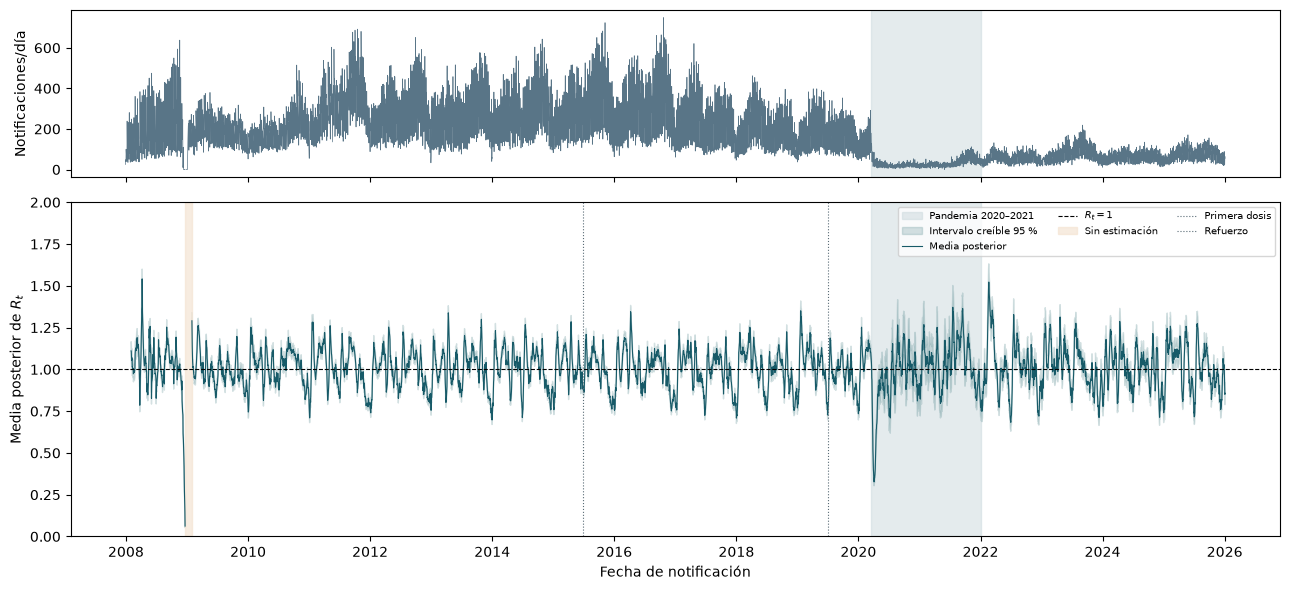

,count,mean,median
lunes,939,220.0,207.0
martes,939,201.9,200.0
miércoles,939,181.1,189.0
jueves,939,177.5,179.0
viernes,939,192.7,196.0
sábado,939,242.5,217.0
domingo,939,88.7,91.0


Estimaciones diarias: 6,507; días sin dato: 7


In [6]:
# Top: observed daily notifications. Bottom: the posterior summary of R_t.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
# Use epidemiological weeks: 2020-S12 starts on 2020-03-15
# and 2021-S52 ends on 2022-01-01.
inicio_pandemia = result.loc[(result.year == 2020) & (result.week == 12), "date"].min()
fin_pandemia = result.loc[(result.year == 2021) & (result.week == 52), "date"].max() + pd.Timedelta(days=1)
assert pd.notna(inicio_pandemia) and pd.notna(fin_pandemia)
ax1.axvspan(inicio_pandemia, fin_pandemia, color="#cbd8dd", alpha=.5)
ax1.plot(result.date, result.notifications, lw=.5, color="#597587")
ax1.set_ylabel("Notificaciones/día")
ax2.axvspan(inicio_pandemia, fin_pandemia, color="#cbd8dd", alpha=.5, label="Pandemia 2020–2021")
ax2.fill_between(result.date, result.rt_lower_95, result.rt_upper_95, color="#5a8d92", alpha=.25,
                 label="Intervalo creíble 95 %")
ax2.plot(result.date, result.rt, lw=.8, color="#175a68", label="Media posterior")
ax2.axhline(1, color="black", ls="--", lw=.8, label="$R_t=1$")
# This band marks the missing week and subsequent days lacking sufficient history.
ax2.axvspan(pd.Timestamp("2008-12-21"), pd.Timestamp("2009-01-30"),
            color="#f5e4d3", alpha=.7, label="Sin estimación")
for event, label in (("2015-07-01", "Primera dosis"), ("2019-07-01", "Refuerzo")):
    ax2.axvline(pd.Timestamp(event), color="#596b75", ls=":", lw=.8, label=label)
ax2.set(ylabel="Media posterior de $R_t$", xlabel="Fecha de notificación", ylim=(0, 2))
ax2.legend(loc="upper right", ncol=3, fontsize=7)
plt.tight_layout()
plt.show()
# Summarize reporting-day effects without modifying the fitted model.
weekday = (result.loc[result.notifications.notna()].assign(dia=lambda d: d.date.dt.dayofweek)
           .groupby("dia").notifications.agg(["count", "mean", "median"]))
weekday.index = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
display(weekday.round(1))
print(f"Estimaciones diarias: {result.rt.notna().sum():,}; días sin dato: {result.notifications.isna().sum()}")

## 7. Sensibilidad a supuestos

**Escenario base.** `result`, calculado en la sección 5, usa los mismos conteos diarios `daily` de Sivigila, media y desviación estándar seriales **14,1 y 2,4 días** (estimación de Simpson resumida por [Vink et al., 2014](https://doi.org/10.1093/aje/kwu209)), ventana de **14 días** y previa Gamma con media y desviación estándar **5 y 5**. La etiqueta `"Simpson, 14 días"` apunta a ese resultado ya calculado; no vuelve a ejecutar el estimador.

Todos los escenarios mantienen los **mismos conteos diarios y la misma previa**. Cada alternativa modifica solo un grupo de supuestos:

| Escenario | Media y DE del intervalo serial | Ventana de estimación | Diferencia frente a la base |
| --- | --- | --- | --- |
| Simpson, 14 días | 14,1 y 2,4 días | 14 días | Ninguna: es `result` |
| Vally, 14 días | 13,1 y 2,2 días | 14 días | Solo cambian los parámetros seriales |
| Lai, 14 días | 14,2 y 1,3 días | 14 días | Solo cambian los parámetros seriales |
| Simpson, 7 días | 14,1 y 2,4 días | 7 días | Solo cambia la longitud de ventana |
| Simpson, 21 días | 14,1 y 2,4 días | 21 días | Solo cambia la longitud de ventana |

Vally y Lai son otras estimaciones bibliográficas presentadas por Vink et al.; no son intervalos colombianos. Una **ventana** es el número de días cuyos conteos se reúnen para estimar un único $R_t$. Por ejemplo, la ventana de 7 días deja que la estimación cambie más deprisa; la de 21 días reúne más datos y suaviza más. La de 7 días es menor que la media serial y se incluye solo para examinar sensibilidad.

Para comparar justamente, `means.dropna().index` selecciona los días con una media posterior disponible en **los cinco escenarios**. Para cada día comparable $d$, `base[d]` es la media posterior del escenario Simpson–14 días y `means[name][d]` la del escenario indicado. La tabla resume:

- **`escenario`**: la combinación de parámetros seriales y longitud de ventana de la fila.
- **`diferencia_absoluta_mediana`**: mediana, entre días comparables, de $|\overline R_d^{\mathrm{escenario}}-\overline R_d^{\mathrm{base}}|$. Indica la diferencia habitual en la **media posterior**.
- **`diferencia_absoluta_máxima`**: el mayor valor de esa diferencia diaria; señala el día de mayor discrepancia, sin decir cuánto dura.
- **`anchura_relativa_mediana_%`**: mediana de $100\,(R_{d,97{,}5}-R_{d,2{,}5})/\overline R_d$ para el escenario de la fila. Mide la anchura de su intervalo creíble **respecto de su propia media**; no es la diferencia frente a la base.
- **`días_que_cambian_lado_de_1`**: número de días comparables en que la **media posterior** queda por encima de 1 en un escenario y no en el otro. No compara intervalos creíbles ni demuestra crecimiento o descenso biológico.

En la fila base, ambas diferencias y el conteo de cambios de lado son cero por construcción; su anchura relativa describe la propia incertidumbre posterior. Una ventana más larga puede estrechar la banda condicional y suavizar cambios, pero supone estabilidad de $R_t$ durante más tiempo. La comparación no identifica qué escenario refleja mejor las infecciones reales ni corrige retrasos de registro.

In [7]:
# The baseline result was computed with Simpson moments and a 14-day window.
# All alternatives use the same daily counts and Gamma prior (mean=SD=5).
variants = {
    "Simpson, 14 días": result,
    "Vally, 14 días": estimate_daily(daily, mean_si=13.1, sd_si=2.2, window_days=14),
    "Lai, 14 días": estimate_daily(daily, mean_si=14.2, sd_si=1.3, window_days=14),
    "Simpson, 7 días": estimate_daily(daily, mean_si=14.1, sd_si=2.4, window_days=7),
    "Simpson, 21 días": estimate_daily(daily, mean_si=14.1, sd_si=2.4, window_days=21),
}
window_lengths = {
    "Simpson, 14 días": 14,
    "Vally, 14 días": 14,
    "Lai, 14 días": 14,
    "Simpson, 7 días": 7,
    "Simpson, 21 días": 21,
}
# Keep only dates where all five posterior means are available.
means = pd.DataFrame({name: variant.rt for name, variant in variants.items()})
comparable = means.dropna().index
baseline_mean = means.loc[comparable, "Simpson, 14 días"]
descriptive_rows = []
for name, variant in variants.items():
    mean_difference = (means.loc[comparable, name] - baseline_mean).abs()
    relative_width = ((variant.rt_upper_95 - variant.rt_lower_95) / variant.rt).loc[comparable]
    descriptive_rows.append({
        "escenario": name,
        "diferencia_absoluta_mediana": mean_difference.median(),
        "diferencia_absoluta_máxima": mean_difference.max(),
        "anchura_relativa_mediana_%": 100 * relative_width.median(),
        "días_que_cambian_lado_de_1": int(
            ((means.loc[comparable, name] > 1) != (baseline_mean > 1)).sum()
        ),
    })
print(f"Días comparables: {len(comparable):,}")
display(pd.DataFrame(descriptive_rows).round(3))

Días comparables: 6,493


,escenario,diferencia_absoluta_mediana,diferencia_absoluta_máxima,anchura_relativa_mediana_%,días_que_cambian_lado_de_1
0,"Simpson, 14 días",0.000,0.000,7.531,0
1,"Vally, 14 días",0.007,0.051,7.531,146
2,"Lai, 14 días",0.004,0.060,7.531,75
3,"Simpson, 7 días",0.047,0.537,10.640,1103
4,"Simpson, 21 días",0.033,0.355,6.132,913


### Distribuciones posteriores, predicción y acuerdo de régimen

Las diferencias entre medias no describen toda la posterior. En cada escenario recuperamos sus parámetros de **forma** $\alpha_{t,\tau}=1+\sum_{d=t-\tau+1}^{t}I_d$ y **tasa** $\beta_{t,\tau}=0{,}2+\sum_{d=t-\tau+1}^{t}\Lambda_d$. Comprobamos que $\alpha/\beta$ y los cuantiles de esa Gamma reproducen las columnas calculadas por `estimate_daily`. Los mismos **6.493 días** de `comparable` se usan para las comparaciones distribucionales y de régimen.

**1. Superposición de posteriores.** El coeficiente de Bhattacharyya $BC_t=\int_0^\infty\sqrt{f_{\rm base}(r)f_{\rm escenario}(r)}\,dr$ vale 1 para distribuciones idénticas y se aproxima a 0 cuando apenas se superponen. Para dos Gamma de forma $\alpha_1,\alpha_2$ y tasa $\beta_1,\beta_2$, calculamos en escala logarítmica

$$\log BC_t=\operatorname{gammaln}\!\left(\frac{\alpha_1+\alpha_2}{2}\right)-\frac{\operatorname{gammaln}(\alpha_1)+\operatorname{gammaln}(\alpha_2)}{2}+\frac{\alpha_1\log\beta_1+\alpha_2\log\beta_2}{2}-\frac{\alpha_1+\alpha_2}{2}\log\!\left(\frac{\beta_1+\beta_2}{2}\right).$$

Mostramos la mediana de $BC_t$ y el porcentaje de días con $BC_t\geq0{,}95$. Ese umbral es un **criterio descriptivo** de alta superposición, no una prueba de igualdad estadística.

**2. Predicción a un día y APE.** Siguiendo la idea de *accumulated prediction error* de [Parag y Donnelly (2020)](https://doi.org/10.1371/journal.pcbi.1007990), usamos la posterior del día $t$ para predecir el conteo observado del día $t+1$, sin incluirlo en el ajuste. Al integrar $R_t$ en la verosimilitud Poisson, obtenemos

$$I_{t+1}\mid I_{\leq t}\sim\operatorname{NegBin}\!\left(n=\alpha_{t,\tau},\ p=\frac{\beta_{t,\tau}}{\beta_{t,\tau}+\Lambda_{t+1}}\right),\qquad \ell_t=-\log\Pr(I_{t+1}\mid I_{\leq t}).$$

Cada escenario usa **su propia** infectividad $\Lambda_{t+1}$, calculada con sus pesos seriales y solo con casos conocidos hasta $t$. Se suman pérdidas $\ell_t$ sobre los **mismos días predictivos**: posterior válida para los cinco escenarios en $t$, conteo observado en $t+1$ e infectividad positiva para todos. $\Delta\mathrm{APE}=\sum_t(\ell_t^{\rm escenario}-\ell_t^{\rm base})$ es negativo si el escenario predice mejor que la base y positivo si predice peor. La prueba pareada de rangos con signo de Wilcoxon evalúa las diferencias diarias de pérdida; para la fila base no hay prueba porque todas sus diferencias son cero. Dado que las ventanas se solapan y los días son dependientes, los **valores $p$ son nominales y exploratorios**, no evidencia independiente de miles de réplicas. Además, el criterio evalúa **notificaciones futuras**, no infecciones futuras.

**3. Régimen con incertidumbre.** Clasificamos cada día por su intervalo creíble del 95 %: $+1$ si el límite inferior supera 1, $-1$ si el superior está por debajo de 1, y $0$ si el intervalo contiene 1. `inversiones_estrictas_IC95` cuenta días con $+1$ en una ruta y $-1$ en la otra. `kappa_IC95` mide acuerdo entre las tres clases mediante $\kappa$ de Cohen con pesos cuadráticos para el orden $(-1,0,+1)$; vale 1 para acuerdo perfecto. Como los intervalos son **condicionales al modelo**, estas clases no representan certeza epidemiológica absoluta.

In [8]:
from scipy.special import gammaln
from scipy.stats import nbinom, wilcoxon


def posterior_parameters(variant, window_days):
    """Return daily Gamma shape and rate for the specified window length."""
    shape = 1 + variant.notifications.rolling(window_days, min_periods=window_days).sum()
    rate = 0.2 + variant.infectiousness.rolling(window_days, min_periods=window_days).sum()
    eligible = variant.rt.notna()
    np.testing.assert_allclose((shape / rate)[eligible], variant.rt[eligible], rtol=1e-8)
    np.testing.assert_allclose(
        gamma.ppf(.025, a=shape[eligible], scale=1 / rate[eligible]),
        variant.rt_lower_95[eligible], rtol=1e-8,
    )
    np.testing.assert_allclose(
        gamma.ppf(.975, a=shape[eligible], scale=1 / rate[eligible]),
        variant.rt_upper_95[eligible], rtol=1e-8,
    )
    return shape.to_numpy(), rate.to_numpy()


def gamma_bhattacharyya(shape_a, rate_a, shape_b, rate_b):
    """Evaluate the closed-form overlap of two Gamma densities in log space."""
    average_shape = (shape_a + shape_b) / 2
    log_overlap = (
        gammaln(average_shape)
        - (gammaln(shape_a) + gammaln(shape_b)) / 2
        + shape_a * np.log(rate_a) / 2
        + shape_b * np.log(rate_b) / 2
        - average_shape * np.log((rate_a + rate_b) / 2)
    )
    # Round-off can make log(BC) slightly positive when the densities coincide.
    return np.exp(np.minimum(log_overlap, 0))


def credible_state(variant, indices):
    """Classify a 95% credible interval relative to the threshold of one."""
    lower = variant.rt_lower_95.to_numpy()[indices]
    upper = variant.rt_upper_95.to_numpy()[indices]
    return np.where(lower > 1, 1, np.where(upper < 1, -1, 0))


def quadratic_cohen_kappa(reference, candidate):
    """Compute weighted Cohen kappa for the ordered states -1, 0, +1."""
    observed = np.zeros((3, 3), dtype=float)
    np.add.at(observed, (reference + 1, candidate + 1), 1)
    observed /= len(reference)
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0))
    distance = (np.subtract.outer(np.arange(3), np.arange(3)) / 2) ** 2
    expected_disagreement = np.sum(distance * expected)
    observed_disagreement = np.sum(distance * observed)
    if expected_disagreement == 0:
        return 1.0 if observed_disagreement == 0 else np.nan
    return 1 - observed_disagreement / expected_disagreement


parameters = {
    name: posterior_parameters(variant, window_lengths[name])
    for name, variant in variants.items()
}
baseline_name = "Simpson, 14 días"
comparison_indices = comparable.to_numpy()

# A predictor on the final calendar day has no next-day observation.
predictor_indices = comparison_indices[comparison_indices + 1 < len(daily)]
next_indices = predictor_indices + 1
observed_next = daily.notifications.to_numpy()[next_indices]
predictive_mask = np.isfinite(observed_next) & (observed_next >= 0)
for variant in variants.values():
    next_infectiousness = variant.infectiousness.to_numpy()[next_indices]
    predictive_mask &= np.isfinite(next_infectiousness) & (next_infectiousness > 0)
predictor_indices = predictor_indices[predictive_mask]
next_indices = predictor_indices + 1
observed_next = daily.notifications.to_numpy()[next_indices]
assert np.all(observed_next == np.floor(observed_next))

# The scenario-specific next-day infectiousness depends only on past cases.
predictive_losses = {}
for name, variant in variants.items():
    shape, rate = parameters[name]
    next_infectiousness = variant.infectiousness.to_numpy()[next_indices]
    success_probability = rate[predictor_indices] / (
        rate[predictor_indices] + next_infectiousness
    )
    loss = -nbinom.logpmf(observed_next, shape[predictor_indices], success_probability)
    assert np.isfinite(loss).all()
    predictive_losses[name] = loss

baseline_shape, baseline_rate = parameters[baseline_name]
baseline_state = credible_state(variants[baseline_name], comparison_indices)
formal_rows = []
for name, variant in variants.items():
    shape, rate = parameters[name]
    overlap = gamma_bhattacharyya(
        baseline_shape[comparison_indices], baseline_rate[comparison_indices],
        shape[comparison_indices], rate[comparison_indices],
    )
    loss_difference = predictive_losses[name] - predictive_losses[baseline_name]
    candidate_state = credible_state(variant, comparison_indices)
    strict_reversals = np.count_nonzero(
        ((baseline_state == 1) & (candidate_state == -1))
        | ((baseline_state == -1) & (candidate_state == 1))
    )
    p_value = np.nan if name == baseline_name else wilcoxon(
        loss_difference, alternative="two-sided", zero_method="wilcox", method="auto"
    ).pvalue
    formal_rows.append({
        "escenario": name,
        "mediana_BC_%": 100 * np.median(overlap),
        "días_con_BC≥0,95_%": 100 * np.mean(overlap >= .95),
        "delta_APE": float(np.sum(loss_difference)),
        "p_valor_Wilcoxon": p_value,
        "inversiones_estrictas_IC95": int(strict_reversals),
        "kappa_IC95": quadratic_cohen_kappa(baseline_state, candidate_state),
    })

formal_results = pd.DataFrame(formal_rows)
formal_display = formal_results.copy()
for column in ("mediana_BC_%", "días_con_BC≥0,95_%", "delta_APE", "kappa_IC95"):
    formal_display[column] = formal_display[column].round(3)
formal_display["p_valor_Wilcoxon"] = formal_results["p_valor_Wilcoxon"].map(
    lambda value: "—" if pd.isna(value) else f"{value:.2e}"
)
print(f"Días con posterior común: {len(comparison_indices):,}")
print(f"Días con predicción de t+1 evaluable: {len(predictor_indices):,}")
display(formal_display)


Días con posterior común: 6,493
Días con predicción de t+1 evaluable: 6,491


,escenario,mediana_BC_%,"días_con_BC≥0,95_%",delta_APE,p_valor_Wilcoxon,inversiones_estrictas_IC95,kappa_IC95
0,"Simpson, 14 días",100.000,100.000,0.000,—,0,1.000
1,"Vally, 14 días",98.808,80.594,2050.596,2.88e-39,0,0.972
2,"Lai, 14 días",99.568,94.486,-2988.755,5.73e-17,0,0.980
3,"Simpson, 7 días",66.940,13.153,-7243.290,5.99e-56,145,0.737
4,"Simpson, 21 días",71.010,17.942,1831.464,2.82e-08,108,0.804


### Conclusiones de sensibilidad

En **6.493 días** con posterior en los cinco escenarios, Vally y Lai mantienen una **alta superposición** con Simpson–14 días: la mediana de $BC$ es **98,808 %** y **99,568 %**, respectivamente. El umbral $BC\geq0{,}95$ se cumple en **80,6 %** y **94,5 %** de esos días. Sus $\kappa$ ponderados son **0,972** y **0,980**, sin inversiones estrictas de crecimiento a descenso o viceversa. Esto respalda **estabilidad práctica del régimen clasificado** frente a esos dos intervalos seriales; no implica igualdad exacta de las posteriores ni validación del intervalo serial para Colombia.

Para las ventanas, la superposición y el acuerdo son menores: Simpson–7 días da $BC$ mediano **66,940 %**, $\kappa=0{,}737$ y **145** inversiones estrictas; Simpson–21 días da **71,010 %**, $\kappa=0{,}804$ y **108** inversiones. La duración de la ventana cambia más el resultado que Vally o Lai en estas comparaciones.

En **6.491 predicciones comunes** a un día, la ventana de **7 días** tiene el menor APE entre las tres duraciones ensayadas: $\Delta\mathrm{APE}=-7.243{,}29$ frente a la base de 14 días; la de 21 días tiene $+1.831{,}46$. Por tanto, **este criterio no favorece ni desempata a favor de la ventana de 14 días**. Lai también mejora el APE respecto de Simpson con 14 días ($-2.988{,}76$), mientras Vally lo empeora ($+2.050{,}60$). Los valores $p$ de Wilcoxon de la tabla describen diferencias pareadas diarias, pero las ventanas solapadas y la dependencia temporal impiden leerlos como pruebas independientes concluyentes. El menor APE evalúa capacidad predictiva de **notificaciones** bajo la Poisson–Gamma; no demuestra que 7 días sea la mejor duración para reconstruir la transmisión biológica. El fuerte patrón de registro por día de la semana y la posible sobredispersión son límites relevantes para esa elección.

### Comparación con el método semanal

El [método semanal](02_rt_nacional.ipynb) reconstruye una secuencia diaria a partir de totales semanales; este usa el día de notificación de cada registro. Ambos comparten los momentos seriales, la discretización, la previa y ventanas de 14 días, pero difieren en la incidencia diaria de entrada y en la regla de historia suficiente tras el vacío. Comparamos el $R_t$ del **sábado de cierre** de cada semana con resultado en ambas rutas. La diferencia cuantifica el efecto **conjunto** de esas decisiones y no prueba que una curva se aproxime mejor a la transmisión real. En particular, ambas rutas heredan sesgos de notificación.

In [9]:
# Reference route reconstructs daily counts from weekly totals.
weekly = pd.read_csv(ROOT / "docs/data_processed/numero_reproductivo/rt_national_weekly.csv")
# Match estimates at the final day of each epidemiological week.
saturdays = result.loc[result.date.dt.dayofweek.eq(5), ["date", "year", "week", "rt"]]
# Join on epidemiological year and week to keep shared window ends.
comparison = saturdays.merge(weekly[["year", "week", "rt"]], on=["year", "week"],
                             suffixes=("_daily", "_weekly")).dropna()
absolute = (comparison.rt_daily - comparison.rt_weekly).abs()
print(f"Semanas comparables: {len(comparison):,}; diferencia absoluta mediana: "
      f"{absolute.median():.4f}; máxima: {absolute.max():.4f}")
display(comparison.tail())

Semanas comparables: 931; diferencia absoluta mediana: 0.0062; máxima: 0.0557


,date,year,week,rt_daily,rt_weekly
935,2025-12-06,2025,49,0.806644,0.809250
936,2025-12-13,2025,50,0.809189,0.820471
937,2025-12-20,2025,51,0.970131,0.960441
938,2025-12-27,2025,52,1.029998,1.012783
939,2026-01-03,2025,53,0.856936,0.871944


## 8. Reproducción, alcance y límites

Desde la raíz, `python scripts/rt_daily_sivigila.py` lee los [CSV copiados](../data/sivigila/csv/), aplica los filtros, comprueba las sumas semanales y genera [`docs/data_processed/numero_reproductivo/rt_national_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_daily.csv). El archivo contiene `date`, año y semana epidemiológicos, `notifications`, `missing_week`, `infectiousness` (el valor **diario** de $\Lambda_d$), media y límites 95 % de $R_t$, y los parámetros del método. La fuente de la discretización es [`epiestim_parametric_weekly.py`](../scripts/epiestim_parametric_weekly.py); aquí se usa su función de pesos, **no** la reconstrucción semanal. La [comparación con EpiEstim R](04_comparacion_epiestim_r_python.ipynb) valida numéricamente esa función de pesos y la ruta semanal en los tramos ensayados. La ruta diaria completa, incluida la espera por el 99 % de historia serial, se verifica en este cuaderno mediante reconciliación de datos y cálculos posteriores manuales, pero no se ha cotejado con la ejecución diaria de R.

Las notificaciones no identifican infecciones ni pares de transmisión. Pueden cambiar las demoras, el subregistro, la mezcla de edades y municipios, y la contribución de importaciones o del herpes zóster. El modelo Poisson iguala media y varianza condicional; una dispersión real mayor estrecharía indebidamente la banda. Los valores $R_t>1$ y $R_t<1$ sugieren crecimiento o descenso **dentro de este modelo aplicado a notificaciones**. $R_0$, el número reproductivo básico en una población totalmente susceptible, es otra magnitud. Ninguna oscilación del gráfico identifica por sí sola el efecto causal de vacunación, clima o calendario escolar.